# Saúde e condicionamento físico: o que diferencia quem está em forma

**Objetivo:** explorar os hábitos e indicadores de saúde de 2.000 pessoas e testar dois modelos:
1. prever o **peso** de uma pessoa;
2. prever se a pessoa **está em forma** (`is_fit`).

**Dados:** `fitness_dataset.csv` (Kaggle).

| Coluna | Significado |
|---|---|
| `age` | idade (anos) |
| `height_cm` / `weight_kg` | altura (cm) e peso (kg) |
| `heart_rate` | frequência cardíaca em repouso (bpm) |
| `blood_pressure` | pressão arterial (mmHg) |
| `sleep_hours` | horas de sono por noite |
| `nutrition_quality` | qualidade da alimentação (0 a 10) |
| `activity_index` | nível de atividade física (1 a 5) |
| `smokes` | fuma (1) ou não (0) |
| `gender` | sexo (M ou F) |
| `is_fit` | está em forma (1) ou não (0) |

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, ConfusionMatrixDisplay

In [2]:
df = pd.read_csv('csv/fitness_dataset.csv')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   age                2000 non-null   int64  
 1   height_cm          2000 non-null   int64  
 2   weight_kg          2000 non-null   int64  
 3   heart_rate         2000 non-null   float64
 4   blood_pressure     2000 non-null   float64
 5   sleep_hours        1840 non-null   float64
 6   nutrition_quality  2000 non-null   float64
 7   activity_index     2000 non-null   float64
 8   smokes             2000 non-null   str    
 9   gender             2000 non-null   str    
 10  is_fit             2000 non-null   int64  
dtypes: float64(5), int64(4), str(2)
memory usage: 172.0 KB


In [3]:
df.head()

,age,height_cm,weight_kg,heart_rate,blood_pressure,sleep_hours,nutrition_quality,activity_index,smokes,gender,is_fit
0,56,152,65,69.6,117.0,NaN,2.37,3.97,no,F,1
1,69,186,95,60.8,114.8,7.5,8.77,3.19,0,F,1
2,46,192,103,61.4,116.4,NaN,8.20,2.03,0,F,0
3,32,189,83,60.2,130.1,7.0,6.18,3.68,0,M,1
4,60,175,99,58.1,115.8,8.0,9.95,4.83,yes,F,1


## 1. Limpeza dos dados

In [4]:
df['smokes'].value_counts()

smokes
yes    711
0      581
no     518
1      190
Name: count, dtype: int64

A coluna `smokes` mistura dois jeitos de escrever a mesma coisa: `yes`/`no` e `1`/`0`. Antes de qualquer análise, tudo vira 1 (fuma) ou 0 (não fuma).

In [5]:
df['smokes'] = df['smokes'].replace({'yes': '1', 'no': '0'}).astype(int)
df['gender_M'] = (df['gender'] == 'M').astype(int)

df['smokes'].value_counts()

smokes
0    1099
1     901
Name: count, dtype: int64

In [6]:
faltando = df['sleep_hours'].isna().sum()
print(f'Linhas sem horas de sono: {faltando} ({faltando / len(df):.0%} da base)')

Linhas sem horas de sono: 160 (8% da base)


Em vez de apagar essas 160 pessoas (8% da base, que têm todas as outras informações), os valores faltando de `sleep_hours` são preenchidos com a **mediana** dentro do modelo, mais adiante. Nas análises abaixo, o pandas simplesmente ignora os valores vazios.

## 2. Análise exploratória

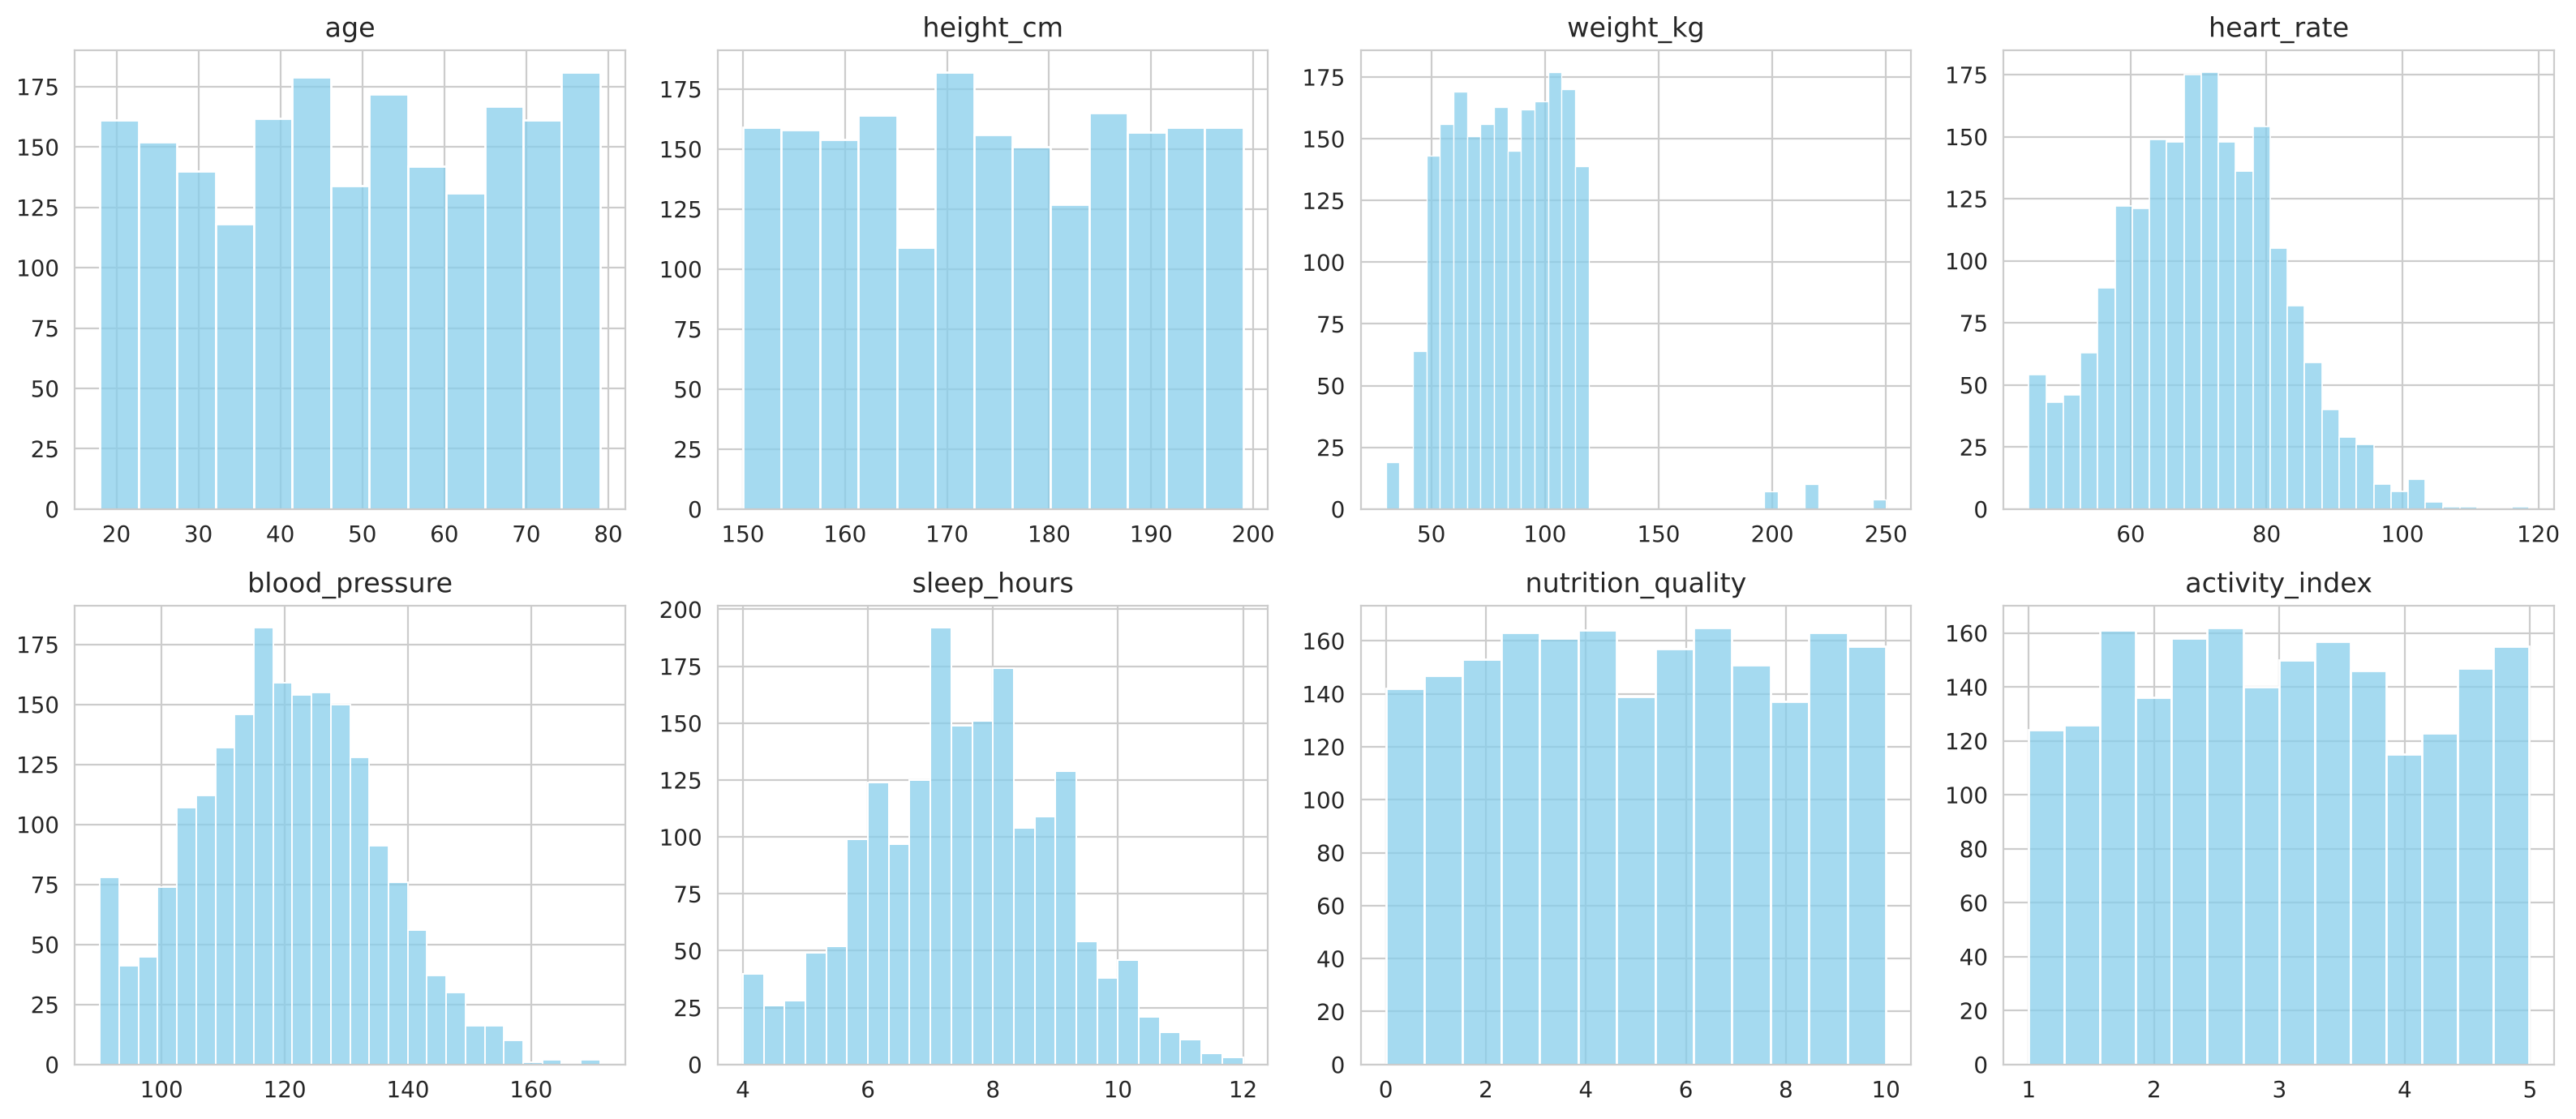

In [7]:
colunas_numericas = ['age', 'height_cm', 'weight_kg', 'heart_rate', 'blood_pressure',
                     'sleep_hours', 'nutrition_quality', 'activity_index']

with sns.axes_style('whitegrid'):
    fig, eixos = plt.subplots(2, 4, figsize=(16, 7))
    for coluna, eixo in zip(colunas_numericas, eixos.flat):
        sns.histplot(data=df, x=coluna, color='skyblue', ax=eixo)
        eixo.set(title=coluna, xlabel='', ylabel='')
    plt.tight_layout()
    plt.show()

In [8]:
print(f"Pessoas com menos de 40 kg: {(df['weight_kg'] < 40).sum()}")
print(f"Pessoas com mais de 150 kg: {(df['weight_kg'] > 150).sum()} (máximo: {df['weight_kg'].max()} kg)")

Pessoas com menos de 40 kg: 19
Pessoas com mais de 150 kg: 21 (máximo: 250 kg)


Idade, altura, horas de sono, alimentação e atividade física estão bem espalhadas, sem concentrações estranhas.

O **peso** vai de 30 a 250 kg: 19 pessoas têm menos de 40 kg e 21 têm mais de 150 kg. Para adultos de 150 a 199 cm, alguns desses valores são pouco realistas e podem ser erros de registro. Como são só 2% da base, eles ficam, mas numa base real valeria investigar.

### Por faixa etária

Com 62 idades diferentes, um gráfico com uma barra por idade fica difícil de ler. Agrupando por **faixa etária**, as tendências aparecem com mais clareza:

In [9]:
df['faixa_etaria'] = pd.cut(df['age'], bins=[17, 29, 39, 49, 59, 69, 79],
                           labels=['18-29', '30-39', '40-49', '50-59', '60-69', '70-79'])

por_faixa = df.groupby('faixa_etaria', observed=True).agg(
    pessoas=('age', 'size'),
    peso_medio=('weight_kg', 'mean'),
    freq_cardiaca=('heart_rate', 'mean'),
    pressao=('blood_pressure', 'mean'),
    horas_sono=('sleep_hours', 'mean'),
    nutricao=('nutrition_quality', 'mean'),
    atividade=('activity_index', 'mean'),
    pct_fumantes=('smokes', 'mean'),
    pct_em_forma=('is_fit', 'mean'),
).round(2)

por_faixa[['pct_fumantes', 'pct_em_forma']] = (por_faixa[['pct_fumantes', 'pct_em_forma']] * 100).round(1)
por_faixa

,pessoas,peso_medio,freq_cardiaca,pressao,horas_sono,nutricao,atividade,pct_fumantes,pct_em_forma
faixa_etaria,,,,,,,,,
18-29,375,81.63,71.17,121.16,7.53,4.98,2.98,44.0,55.0
30-39,284,84.52,70.36,119.85,7.62,4.75,2.88,45.0,46.0
40-49,344,83.83,69.70,119.48,7.57,5.22,3.02,47.0,44.0
50-59,334,82.32,70.06,119.48,7.52,5.25,3.06,51.0,35.0
60-69,321,84.79,70.02,120.22,7.35,5.03,2.99,38.0,34.0
70-79,342,84.55,70.33,119.15,7.50,4.94,3.05,45.0,24.0


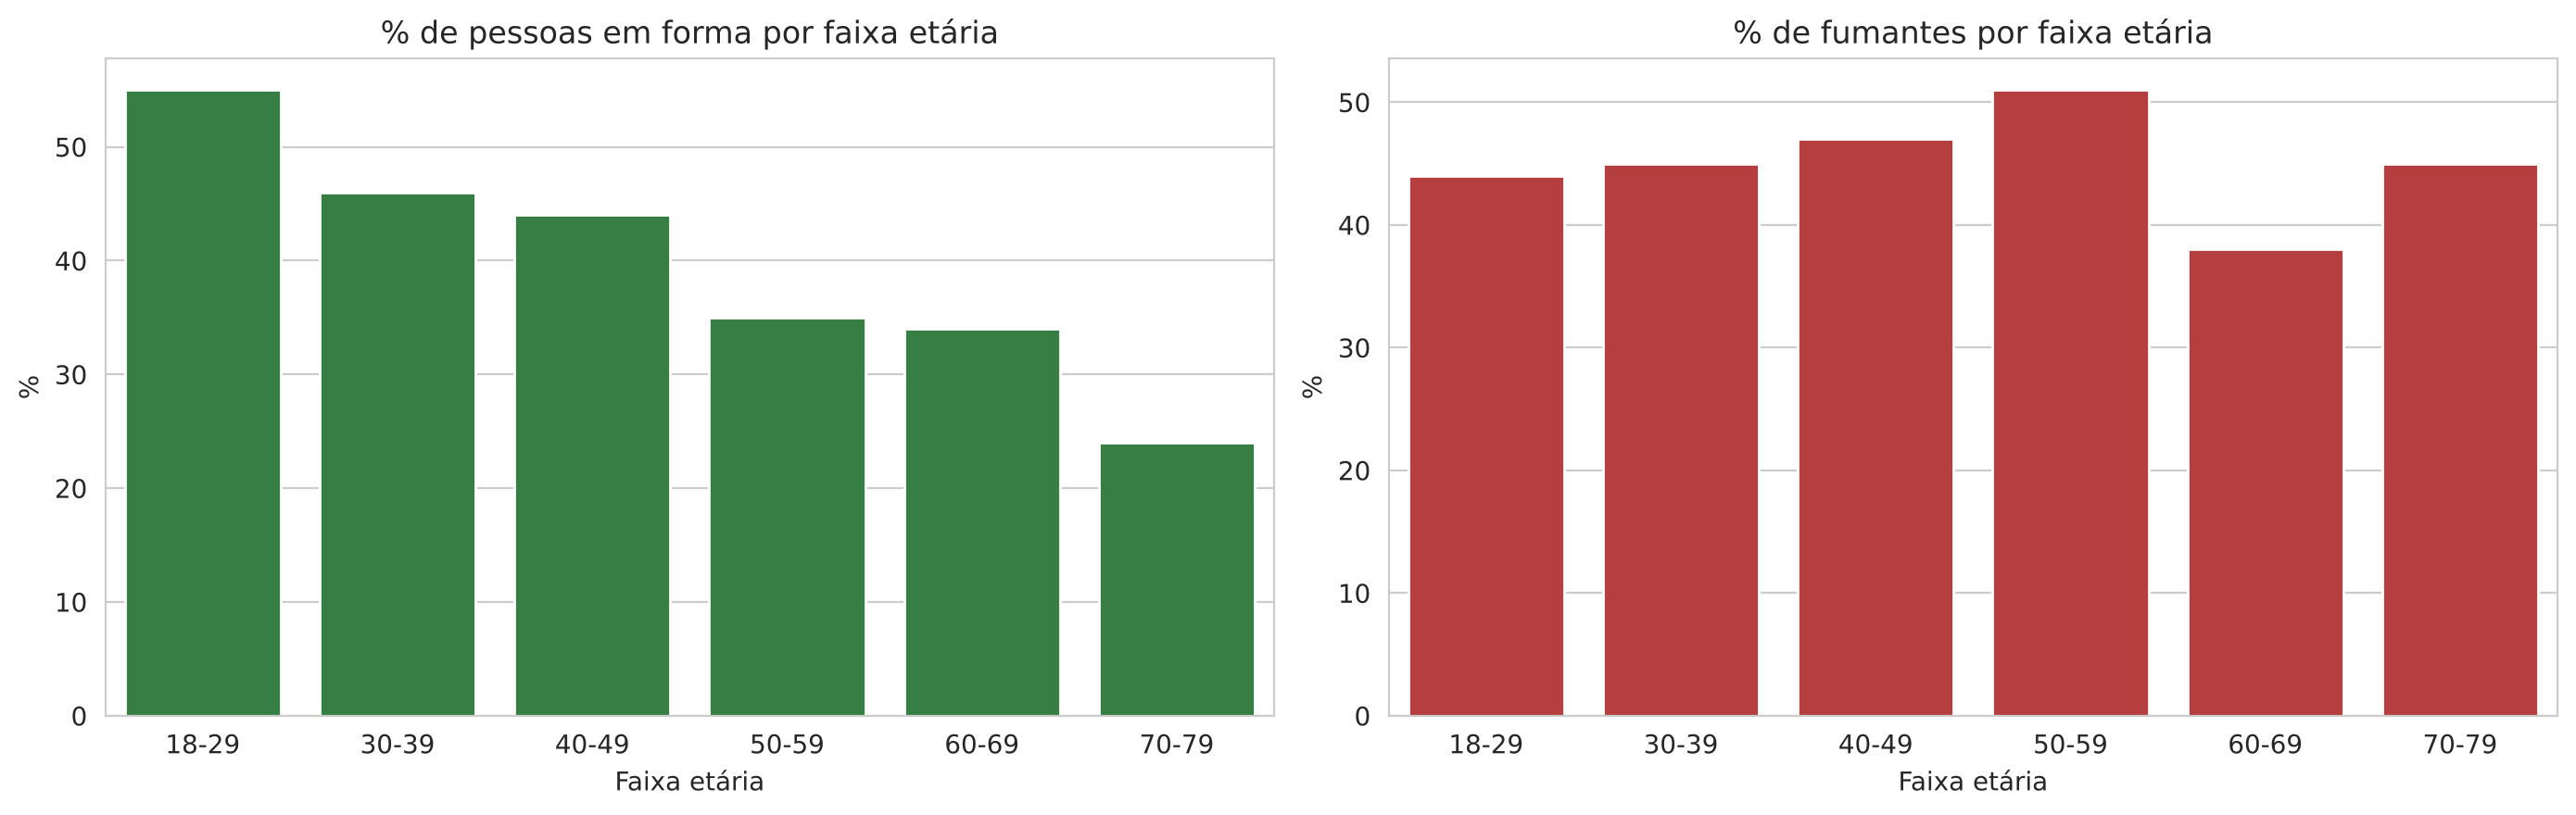

In [10]:
with sns.axes_style('whitegrid'):
    fig, eixos = plt.subplots(1, 2, figsize=(14, 4.5))
    sns.barplot(x=por_faixa.index, y=por_faixa['pct_em_forma'], color='#2B8A3E', ax=eixos[0])
    eixos[0].set(title='% de pessoas em forma por faixa etária', xlabel='Faixa etária', ylabel='%')
    sns.barplot(x=por_faixa.index, y=por_faixa['pct_fumantes'], color='#C92A2A', ax=eixos[1])
    eixos[1].set(title='% de fumantes por faixa etária', xlabel='Faixa etária', ylabel='%')
    plt.tight_layout()
    plt.show()

A **porcentagem de pessoas em forma cai com a idade**: 55% entre 18 e 29 anos e 24% entre 70 e 79.

Já peso, frequência cardíaca, pressão, sono, alimentação e atividade física quase não mudam de uma faixa para outra. A porcentagem de fumantes também não segue um padrão (fica entre 38% e 51%).

### Quem está em forma x quem não está

In [11]:
df.groupby('is_fit')[['age', 'weight_kg', 'heart_rate', 'blood_pressure', 'sleep_hours',
                      'nutrition_quality', 'activity_index', 'smokes']].mean().round(2)

,age,weight_kg,heart_rate,blood_pressure,sleep_hours,nutrition_quality,activity_index,smokes
is_fit,,,,,,,,
0,52.24,85.40,69.97,120.52,7.38,4.44,2.68,0.57
1,44.41,80.75,70.76,119.00,7.71,5.93,3.48,0.27


Quem está em forma é, em média, **mais jovem** (44 anos contra 52), **se alimenta melhor** (nota 5,9 contra 4,4), é **mais ativo** (3,5 contra 2,7) e **fuma bem menos** (27% contra 57%). Peso, frequência cardíaca, pressão e sono são parecidos nos dois grupos.

## 3. Correlações

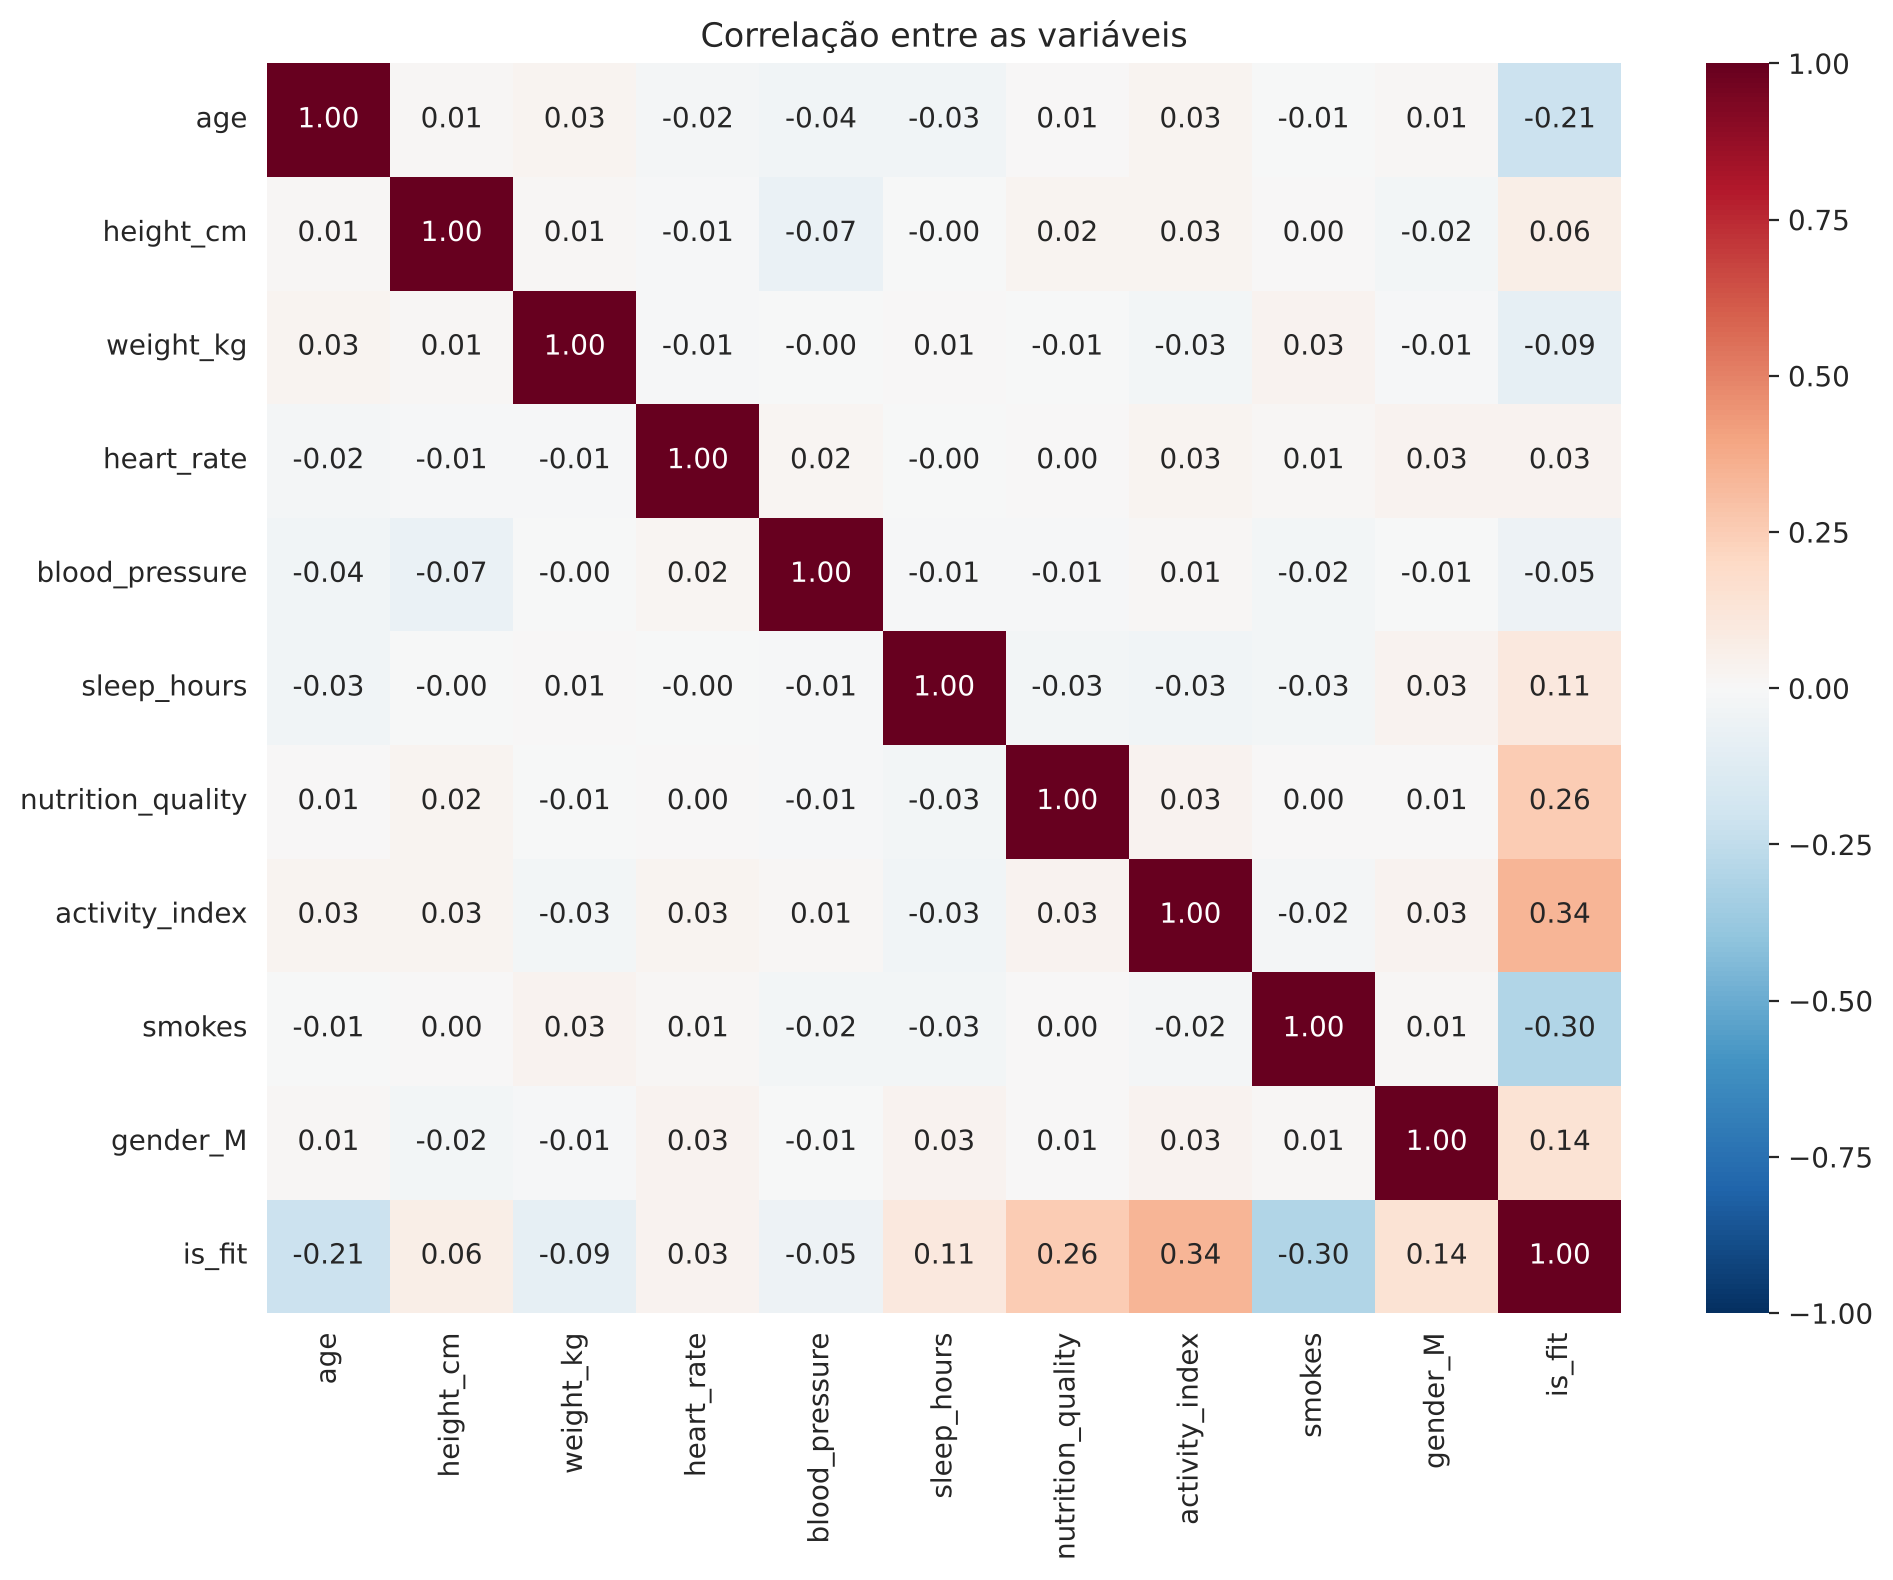

In [12]:
correlacao = df[colunas_numericas + ['smokes', 'gender_M', 'is_fit']].corr()

with sns.axes_style('white'):
    plt.figure(figsize=(10, 8))
    sns.heatmap(correlacao, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1)
    plt.title('Correlação entre as variáveis')
    plt.tight_layout()
    plt.show()

A correlação vai de **−1 a 1** e mede o quanto duas variáveis andam juntas: perto de 1, sobem juntas; perto de −1, quando uma sobe a outra desce; perto de 0, não há relação. Ela **não é uma porcentagem**: uma correlação de 0,0065 não significa que "em 0,65% das vezes" uma sobe junto com a outra, e sim que as duas não têm relação.

- O **peso** não tem correlação com nenhuma variável, nem com a altura (0,01). Na vida real, pessoas mais altas tendem a pesar mais, então isso indica que esta base foi gerada artificialmente, o que é comum em datasets de estudo.
- O **`is_fit`** tem as relações mais claras: atividade física (0,34), fumar (−0,30), alimentação (0,26) e idade (−0,21).

## 4. Dá para prever o peso?

A regressão linear é comparada com um "chute": prever sempre o peso médio. As etapas de preenchimento dos valores faltando e de padronização ficam dentro de um `pipeline`, então são calculadas **só com os dados de treino**.

In [13]:
x = df.drop(columns=['weight_kg', 'gender', 'faixa_etaria'])
y = df['weight_kg']

x_treino, x_teste, y_treino, y_teste = train_test_split(x, y, test_size=0.25, random_state=123)

modelo_peso = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LinearRegression())
modelo_peso.fit(x_treino, y_treino)
y_previsto = modelo_peso.predict(x_teste)

rmse = np.sqrt(mean_squared_error(y_teste, y_previsto))
rmse_media = np.sqrt(mean_squared_error(y_teste, np.full(len(y_teste), y_treino.mean())))

print(f'Erro médio do modelo (RMSE): {rmse:.1f} kg')
print(f'Erro chutando sempre a média: {rmse_media:.1f} kg')
print(f'R²: {r2_score(y_teste, y_previsto):.3f}')

Erro médio do modelo (RMSE): 26.6 kg
Erro chutando sempre a média: 26.7 kg
R²: 0.001


O modelo erra, em média, **26,6 kg**, praticamente o mesmo que chutar o peso médio para todo mundo (26,7 kg). O R² de 0,001 mostra que o modelo não explica quase nada do peso.

Isso bate com as correlações: nenhuma variável desta base tem relação com o peso, então não há o que o modelo aprender. Olhando só o erro de 27 kg, não dá para saber se o modelo é bom ou ruim; comparando com o chute, fica claro que ele não funciona. Por isso vale sempre ter uma referência de comparação.

## 5. Prevendo se a pessoa está em forma

A coluna `is_fit` tem só dois valores (0 ou 1), então este é um problema de **classificação**. O modelo usado é a **regressão logística**, avaliada pela **acurácia** (a porcentagem de acertos).

In [14]:
x = df.drop(columns=['is_fit', 'gender', 'faixa_etaria'])
y = df['is_fit']

x_treino, x_teste, y_treino, y_teste = train_test_split(
    x, y, test_size=0.25, random_state=123, stratify=y
)

modelo = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(max_iter=1000))
modelo.fit(x_treino, y_treino)

acuracia = accuracy_score(y_teste, modelo.predict(x_teste))
acuracia_chute = max(y_teste.mean(), 1 - y_teste.mean())

print(f'Acurácia do modelo: {acuracia:.1%}')
print(f'Acurácia chutando sempre "não está em forma": {acuracia_chute:.1%}')

Acurácia do modelo: 77.4%
Acurácia chutando sempre "não está em forma": 60.0%


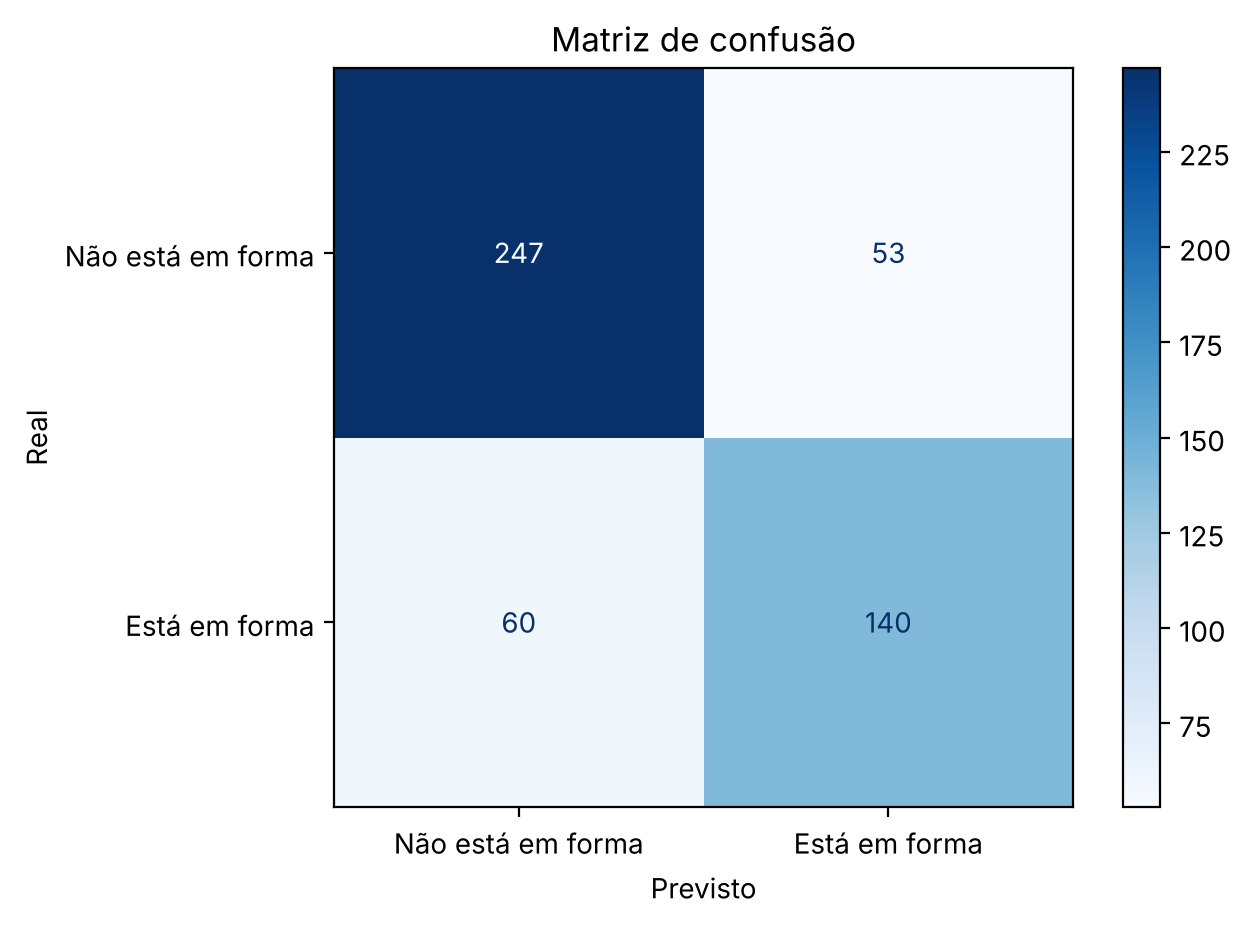

In [15]:
ConfusionMatrixDisplay.from_estimator(
    modelo, x_teste, y_teste, display_labels=['Não está em forma', 'Está em forma'], cmap='Blues'
)
plt.title('Matriz de confusão')
plt.xlabel('Previsto')
plt.ylabel('Real')
plt.show()

In [16]:
coeficientes = pd.Series(modelo[-1].coef_[0], index=x.columns).round(2).sort_values()
coeficientes

smokes              -0.91
age                 -0.70
blood_pressure      -0.25
weight_kg           -0.15
heart_rate           0.09
height_cm            0.19
sleep_hours          0.23
gender_M             0.42
nutrition_quality    0.84
activity_index       0.99
dtype: float64

O modelo acerta **77,4%** das pessoas do teste, contra 60% de quem chutasse sempre "não está em forma", a classe mais comum. Na matriz de confusão, 247 das 300 pessoas fora de forma e 140 das 200 em forma foram classificadas certo.

Como as variáveis foram padronizadas, dá para comparar o tamanho dos coeficientes:
- aumentam a chance de estar em forma: **atividade física** (0,99) e **qualidade da alimentação** (0,84); ser homem também aumenta um pouco (0,42);
- diminuem a chance: **fumar** (−0,91) e **idade** (−0,70);
- frequência cardíaca, altura, peso e pressão têm pouco efeito.

## Conclusão

- Estar em forma está ligado principalmente a **hábitos**: quem pratica mais atividade física, se alimenta melhor e não fuma tem muito mais chance de estar em forma. A idade também pesa: a porcentagem de pessoas em forma cai de 55% (18 a 29 anos) para 24% (70 a 79).
- O **peso não pode ser previsto** com esta base: ele não tem relação com nenhuma das outras variáveis, e o modelo não é melhor que chutar a média.
- Prever se a pessoa **está em forma** funciona bem: a regressão logística acerta 77,4%, contra 60% do chute.
- A coluna `smokes` precisou de limpeza (misturava `yes`/`no` com `1`/`0`), e as horas de sono faltando foram preenchidas com a mediana em vez de apagar 8% da base.